# 02 — Tout le code de préparation et nettoyage : objectif 1

Ce notebook contient directement le téléchargement, le décodage, les contrôles, les jointures et la construction des 24 variables. Exécuter toutes les cellules dans l’ordre. Aucun module du projet, script Python ou autre notebook n’est exécuté ou importé.

Unité : une collision ; cible : gravité enregistrée (1 mortelle, 2 grave, 3 légère). La table victimes vérifie les comptes ; ses blessures et son nombre ne sont jamais des prédicteurs. Les autres objectifs restent pour la suite.


## 1. Bibliothèques, dossiers et variables retenues

Les CSV bruts sont conservés, les tables préparées sont enregistrées localement dans `data/processed/` et ignorées par Git. Les modalités et codes spéciaux viennent du guide officiel DfT fourni dans `references/`.


In [1]:
from xml.etree import ElementTree as ET
from zipfile import ZipFile
import numpy as np
import pandas as pd
from IPython.display import display
from pathlib import Path
ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / "notebooks").is_dir() and (p / "requirements.txt").is_file()), None)
if ROOT is None: raise RuntimeError("Ouvrir ce notebook depuis le dossier road-safety-project ou son sous-dossier notebooks.")
RAW = ROOT / "data/raw"
PROCESSED = ROOT / "data/processed"
YEARS = [2021, 2022, 2023, 2024, 2025]
SOURCE = 'https://www.gov.uk/government/statistical-data-sets/road-safety-open-data'
SEVERITY_GUIDE = 'https://www.gov.uk/government/publications/guide-to-severity-adjustments-for-reported-road-casualty-statistics'
NUM_CONTEXT = ['hour_sin','hour_cos','month_sin','month_cos']
CAT_CONTEXT = ['speed_limit','day_of_week','first_road_class','road_type','light_conditions','weather_conditions','road_surface_conditions','urban_or_rural_area']
NUM_VEHICLES = ['vehicle_count','driver_age_min','driver_age_mean','vehicle_age_mean','young_driver_share','older_driver_share']
CAT_VEHICLES = ['has_cycle','has_motorcycle','has_car','has_goods','has_bus','has_ppt']



## 2. Téléchargement des trois CSV officiels

Le téléchargement n’est lancé que pour un fichier absent ou vide. Les liens « last 5 years » sont glissants : les années sont vérifiées au chargement et les dimensions des trois tables sont présentées.


In [2]:
from urllib.request import urlretrieve
BASE = "https://data.dft.gov.uk/road-accidents-safety-data"
FILES = {
    "collisions_2021_2025.csv": f"{BASE}/dft-road-casualty-statistics-collision-last-5-years.csv",
    "vehicles_2021_2025.csv": f"{BASE}/dft-road-casualty-statistics-vehicle-last-5-years.csv",
    "casualties_2021_2025.csv": f"{BASE}/dft-road-casualty-statistics-casualty-last-5-years.csv",
}
def download_all(force: bool = False) -> None:
    RAW.mkdir(parents=True, exist_ok=True)
    for filename, url in FILES.items():
        destination = RAW / filename
        if destination.exists() and destination.stat().st_size > 0 and not force:
            print(f"Déjà présent : {destination.name} ({destination.stat().st_size / 1_000_000:.1f} Mo)")
            continue
        print(f"Téléchargement : {filename}")
        urlretrieve(url, destination)
        if destination.stat().st_size == 0:
            destination.unlink(missing_ok=True)
            raise RuntimeError(f"Fichier vide reçu depuis {url}")
        print(f"Terminé : {destination.stat().st_size / 1_000_000:.1f} Mo")


## 3. Dictionnaire officiel et règles de nettoyage

Le code ci-dessous lit le classeur DfT, traduit les codes, transforme `-1` en valeur absente et garde les codes non documentés visibles. Les âges négatifs sont manquants ; les plafonds 120 ans pour une personne et 100 ans pour un véhicule sont des hypothèses de plausibilité du projet, pas des seuils officiels. Aucune ligne n’est supprimée à cause d’un prédicteur absent.


In [3]:
def codebook():
    ns = {'m':'http://schemas.openxmlformats.org/spreadsheetml/2006/main'}
    result = {}
    with ZipFile(ROOT / 'references/data_guide_2025.xlsx') as z:
        strings = [''.join(t.text or '' for t in si.findall('.//m:t', ns)) for si in ET.fromstring(z.read('xl/sharedStrings.xml')).findall('m:si',ns)]
        for row in ET.fromstring(z.read('xl/worksheets/sheet1.xml')).findall('.//m:sheetData/m:row',ns):
            cells = {}
            for c in row.findall('m:c',ns):
                v = c.find('m:v',ns)
                value = v.text if v is not None else ''
                if c.get('t') == 's' and value: value = strings[int(value)]
                cells[''.join(x for x in c.get('r','') if x.isalpha())] = value
            try: key = int(float(cells.get('C','')))
            except (ValueError,TypeError): continue
            if cells.get('B') and cells.get('D'): result.setdefault(cells['B'], {})[key] = cells['D']
    return result

def decode(s, field, book):
    values = pd.to_numeric(s,errors='coerce')
    mapping = book.get(field,{})
    labels = values.map(mapping).astype('string')
    # Speed values themselves are valid measurements in the DfT guide.
    if field == 'speed_limit':
        for n in [20,30,40,50,60,70]: labels.loc[values.eq(n)] = str(n)+' mph'
    missing = values.isna() | values.eq(-1)
    unlisted = labels.isna() & ~missing
    labels.loc[unlisted] = 'UNMAPPED_CODE_' + values.loc[unlisted].astype(str)
    labels.loc[missing] = 'MISSING'
    return labels.astype(object)

def vehicle_group(s):
    s = s.fillna('MISSING').astype(str).str.lower()
    out = pd.Series('other',index=s.index,dtype=object)
    patterns = [('cycle','pedal cycle'),('motorcycle','motorcycle'),('car','car|taxi'),('goods','goods'),('bus','bus|coach'),('ppt','personal.*transporter|e[- ]?scooter')]
    for label,pattern in patterns: out.loc[s.str.contains(pattern,regex=True)] = label
    out.loc[s.eq('missing')] = 'unknown'
    return out

def numeric_clean(s, upper=None):
    values = pd.to_numeric(s,errors='coerce').astype(float)
    invalid = values.lt(0)
    if upper is not None: invalid |= values.gt(upper)
    return values.mask(invalid)


In [4]:
# Contrôles ciblés des règles, visibles dans le notebook.
assert vehicle_group(pd.Series(["Personal powered transporter", "Powered personal transporter", "Motorcycle 125cc", "Car", "Pedal cycle", "MISSING"])).tolist() == ["ppt", "ppt", "motorcycle", "car", "cycle", "unknown"]
check_codes = decode(pd.Series([-1, 20, 30, 99, np.nan]), "speed_limit", codebook()).tolist()
assert check_codes[:3] == ["MISSING", "20 mph", "30 mph"]
assert "unknown" in check_codes[3].lower() and check_codes[4] == "MISSING"
check_age = numeric_clean(pd.Series([-1, 0, 25, 120, 121]), 120)
assert pd.isna(check_age.iloc[0]) and pd.isna(check_age.iloc[4])
assert check_age.iloc[1:4].tolist() == [0, 25, 120]
assert not set(NUM_CONTEXT + CAT_CONTEXT + NUM_VEHICLES + CAT_VEHICLES) & {"target", "collision_severity", "number_of_casualties", "year", "police_force", "collision_index"}
print("Les quatre contrôles de préparation passent.")


Les quatre contrôles de préparation passent.


## 4. Chargement, clés, doublons et relations

On bloque en cas de clé absente/dupliquée, de ligne orpheline ou de comptage incohérent. Aucun doublon n’est supprimé silencieusement. Les années des enregistrements enfants sont comparées à celles des collisions.


In [5]:
def load_sources():
    files = {kind: RAW / f'{kind}_2021_2025.csv' for kind in ['collisions','vehicles','casualties']}
    if not all(p.exists() for p in files.values()):
        download_all()
    data = {name:pd.read_csv(path,low_memory=False) for name,path in files.items()}
    manifests = []
    for name,df in data.items():
        path=files[name]
        years=sorted(df.collision_year.dropna().astype(int).unique().tolist())
        if years != YEARS: raise ValueError(f'{name}: années {years}; attendues {YEARS}. Le lien glissant DfT peut avoir changé.')
        singular={'collisions':'collision','vehicles':'vehicle','casualties':'casualty'}[name]
        manifests.append(dict(table=name,rows=len(df),columns=len(df.columns),bytes=path.stat().st_size,years=years,url=f'https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-{singular}-last-5-years.csv'))
    return data,manifests

sources,manifest=load_sources()
c,v,q = sources['collisions'],sources['vehicles'],sources['casualties']
audit={'sources':manifest,'keys':{},'cleaning':{},'joins':{}}
for name,df,key in [('collisions',c,['collision_index']),('vehicles',v,['collision_index','vehicle_reference']),('casualties',q,['collision_index','casualty_reference'])]:
    audit['keys'][name]={'null_key_rows':int(df[key].isna().any(axis=1).sum()),'duplicate_key_rows':int(df.duplicated(key).sum()),'exact_duplicate_rows':int(df.duplicated().sum())}
    if audit['keys'][name]['null_key_rows'] or audit['keys'][name]['duplicate_key_rows']: raise ValueError(f'Clé invalide dans {name}; inspection requise avant suppression.')
collision_keys=set(c.collision_index)
for name,df in [('vehicles',v),('casualties',q)]:
    orphan=int((~df.collision_index.isin(collision_keys)).sum())
    audit['joins'][name+'_without_collision']=orphan
    year_mismatch=int(df.collision_year.ne(df.collision_index.map(c.set_index('collision_index').collision_year)).sum())
    audit['joins'][name+'_year_mismatches']=year_mismatch
    if year_mismatch: raise ValueError('Années incohérentes entre une collision et ses enregistrements enfants.')
    if orphan: raise ValueError('Enregistrements sans collision : traiter la source avant les jointures.')
for kind,df,field in [('vehicles',v,'number_of_vehicles'),('casualties',q,'number_of_casualties')]:
    counts=df.groupby('collision_index').size()
    mismatch=(c.set_index('collision_index')[field] != counts.reindex(c.collision_index).fillna(0).to_numpy()).sum()
    audit['joins'][kind+'_count_mismatches']=int(mismatch)
    if mismatch: raise ValueError('Comptages incohérents entre les tables.')

display(pd.DataFrame(audit["keys"]).T)
display(pd.Series(audit["joins"]).to_frame("Écarts"))


,null_key_rows,duplicate_key_rows,exact_duplicate_rows
collisions,0,0,0
vehicles,0,0,0
casualties,0,0,0


,Écarts
vehicles_without_collision,0
vehicles_year_mismatches,0
casualties_without_collision,0
casualties_year_mismatches,0
vehicles_count_mismatches,0
casualties_count_mismatches,0


## 5. Audit du schéma des trois tables

Le bilan distingue valeurs nulles, codes `-1`, types et nombres de modalités. Les contrôles sont présentés comme tableaux directement dans ce notebook.


In [6]:
book=codebook()
schema=[]
for name,df in sources.items():
    for column in df.columns:
        numeric=pd.api.types.is_numeric_dtype(df[column])
        schema.append(dict(table=name,column=column,dtype=str(df[column].dtype),nulls=int(df[column].isna().sum()),sentinel_minus_one=int(df[column].eq(-1).sum()) if numeric else 0,distinct=int(df[column].nunique())))
audit['schema']=schema

display(pd.DataFrame(schema).sort_values(["table", "nulls"], ascending=[True, False]).head(25))


,table,column,dtype,nulls,sentinel_minus_one,distinct
76,casualties,collision_index,object,0,0,513801
77,casualties,collision_year,int64,0,0,5
78,casualties,collision_ref_no,object,0,0,510837
79,casualties,vehicle_reference,int64,0,0,38
80,casualties,casualty_reference,int64,0,0,145
81,casualties,casualty_class,int64,0,0,3
82,casualties,sex_of_casualty,int64,0,6304,4
83,casualties,age_of_casualty,int64,0,14106,104
84,casualties,age_band_of_casualty,int64,0,14106,12
85,casualties,casualty_severity,int64,0,0,3


## 6. Variables de route et de temps

L’heure et le mois sont représentés par sinus/cosinus pour préserver leur caractère cyclique. Vitesse réglementaire, jour, classe/type de route, lumière, météo, chaussée et urbain/rural sont catégoriels. Les champs ayant changé de spécification en 2024 sont exclus ici jusqu’à harmonisation validée.


In [7]:
base=c[['collision_index','collision_year','police_force','collision_injury_based']+CAT_CONTEXT].copy()
base=base.rename(columns={'collision_year':'year','collision_injury_based':'reporting_regime'})
time=pd.to_datetime(c.time.astype('string'),format='%H:%M',errors='coerce')
date=pd.to_datetime(c.date,dayfirst=True,errors='coerce')
audit['cleaning']['invalid_time']=int(time.isna().sum())
audit['cleaning']['invalid_date']=int(date.isna().sum())
audit['cleaning']['date_year_mismatch']=int((date.dt.year.notna() & date.dt.year.ne(c.collision_year)).sum())
hour=time.dt.hour + time.dt.minute/60
for feature,values,period in [('hour',hour,24),('month',date.dt.month,12)]:
    base[feature+'_sin']=np.sin(2*np.pi*values/period)
    base[feature+'_cos']=np.cos(2*np.pi*values/period)
for column in CAT_CONTEXT: base[column]=decode(c[column],column,book)
base['police_force']=decode(c.police_force,'police_force',book)
base['urban_group']=base.urban_or_rural_area
base['speed_group']=base.speed_limit

display(base.head())


,collision_index,year,police_force,reporting_regime,speed_limit,day_of_week,first_road_class,road_type,light_conditions,weather_conditions,road_surface_conditions,urban_or_rural_area,hour_sin,hour_cos,month_sin,month_cos,urban_group,speed_group
0,202417H105824,2024,Cleveland,1,30 mph,Thursday,Unclassified,Single carriageway,Daylight,Fine no high winds,Dry,Urban,-0.878817,-0.477159,-8.660254e-01,0.500000,Urban,30 mph
1,202517M115025,2025,Cleveland,1,30 mph,Saturday,A,Single carriageway,Darkness - lights lit,Fine no high winds,Dry,Urban,-0.930418,-0.366501,-5.000000e-01,0.866025,Urban,30 mph
2,202517L306225,2025,Cleveland,1,30 mph,Sunday,A,Single carriageway,Darkness - lights lit,Fine no high winds,Dry,Urban,-0.473320,0.880891,1.224647e-16,-1.000000,Urban,30 mph
3,202417S104724,2024,Cleveland,1,60 mph,Saturday,A,Dual carriageway,Daylight,Fine no high winds,Dry,Rural,-0.642788,-0.766044,8.660254e-01,-0.500000,Rural,60 mph
4,202517S106525,2025,Cleveland,1,30 mph,Friday,Unclassified,Single carriageway,Daylight,Fine no high winds,Dry,Urban,0.932008,-0.362438,5.000000e-01,-0.866025,Urban,30 mph


## 7. Agréger les véhicules puis joindre aux collisions

Plusieurs véhicules deviennent une seule ligne par collision : effectif, types présents, âges des conducteurs/véhicules et parts de conducteurs jeunes ou âgés. On ne concatène pas les trois CSV et on ne multiplie pas les lignes de collision par le nombre de véhicules.


In [8]:
# Static vehicle/driver information only, no manoeuvres, impact or injury outcomes.
vs=v[['collision_index','vehicle_reference','vehicle_type','age_of_driver','sex_of_driver','age_of_vehicle']].copy()
vs['vehicle_type_label']=decode(vs.vehicle_type,'vehicle_type',book)
vs['vehicle_group']=vehicle_group(vs.vehicle_type_label)
audit['cleaning']['vehicle_type_unmapped']=int(vs.vehicle_type_label.str.startswith('UNMAPPED_CODE_').sum())
audit['vehicle_groups']=vs.vehicle_group.value_counts().astype(int).to_dict()
audit['cleaning']['driver_age_above_120']=int(vs.age_of_driver.gt(120).sum())
audit['cleaning']['vehicle_age_above_100']=int(vs.age_of_vehicle.gt(100).sum())
vs['driver_age']=numeric_clean(vs.age_of_driver,120)
vs['vehicle_age']=numeric_clean(vs.age_of_vehicle,100)
vs['driver_sex']=decode(vs.sex_of_driver,'sex_of_driver',book)
audit['cleaning']['driver_age_negative_or_over_120']=int(pd.to_numeric(v.age_of_driver,errors='coerce').lt(0).sum()+pd.to_numeric(v.age_of_driver,errors='coerce').gt(120).sum())
audit['cleaning']['vehicle_age_negative_or_over_100']=int(pd.to_numeric(v.age_of_vehicle,errors='coerce').lt(0).sum()+pd.to_numeric(v.age_of_vehicle,errors='coerce').gt(100).sum())
grouped=vs.groupby('collision_index',sort=False)
agg=grouped.agg(vehicle_count=('vehicle_reference','size'),driver_age_min=('driver_age','min'),driver_age_mean=('driver_age','mean'),vehicle_age_mean=('vehicle_age','mean'))
vs['young']=vs.driver_age.lt(25).where(vs.driver_age.notna())
vs['older']=vs.driver_age.ge(65).where(vs.driver_age.notna())
agg['young_driver_share']=vs.groupby('collision_index').young.mean()
agg['older_driver_share']=vs.groupby('collision_index').older.mean()
for group in ['cycle','motorcycle','car','goods','bus','ppt']:
    agg['has_'+group]=vs.vehicle_group.eq(group).groupby(vs.collision_index).max().map({True:'yes',False:'no'})
base=base.merge(agg,on='collision_index',how='left',validate='one_to_one')

display(agg.head())
print("Après jointure :", base.shape)


,vehicle_count,driver_age_min,driver_age_mean,vehicle_age_mean,young_driver_share,older_driver_share,has_cycle,has_motorcycle,has_car,has_goods,has_bus,has_ppt
collision_index,,,,,,,,,,,,
2021622100736,2,14.0,24.500000,10.000000,0.5,0.0,yes,no,yes,no,no,no
2021010319369,2,25.0,36.500000,8.500000,0.0,0.0,no,no,yes,no,no,no
2021122100703,3,50.0,60.333333,7.333333,0.0,0.333333,no,no,yes,no,no,no
2021471117441,2,17.0,22.500000,11.500000,0.5,0.0,no,yes,yes,no,no,no
2021451064862,3,28.0,40.666667,5.000000,0.0,0.0,no,no,yes,no,no,no


Après jointure : (513801, 30)


## 8. Cible, contrat de variables et export local

L’identifiant, l’année, la zone de police et le régime de déclaration servent à la traçabilité ou aux diagnostics, jamais comme prédicteurs. Le nombre de victimes et les champs de gravité ne font pas partie des 24 variables. La cible est vérifiée à nouveau contre la source après la jointure.


In [9]:
# Une ligne par collision ; aucune variable de victime comme prédicteur.
allowed = c.collision_severity.isin([1,2,3])
audit["cleaning"]["invalid_collision_target"] = int((~allowed).sum())
prepared = base.loc[allowed].copy()
prepared["target"] = c.loc[allowed,"collision_severity"].to_numpy()
numeric = NUM_CONTEXT + NUM_VEHICLES
categorical = CAT_CONTEXT + CAT_VEHICLES
features = numeric + categorical
for field in categorical:
    prepared[field] = prepared[field].fillna("MISSING").astype(str)
for field in numeric:
    prepared[field] = pd.to_numeric(prepared[field], errors="coerce")
forbidden = {"target","year","collision_index","police_force","reporting_regime","number_of_casualties","collision_severity"}
assert not set(features) & forbidden
alignment = prepared[["collision_index","target"]].merge(c[["collision_index","collision_severity"]],on="collision_index",validate="one_to_one")
assert alignment.target.eq(alignment.collision_severity).all()
PROCESSED.mkdir(parents=True,exist_ok=True)
prepared.to_csv(PROCESSED/"collision_severity_2021_2025.csv.gz",index=False,compression={"method":"gzip","compresslevel":1})
display(pd.Series(audit["cleaning"],name="Enregistrements concernés").to_frame())
display(prepared.head())
print("Table préparée :", prepared.shape)
print("24 variables prédictives ; CSV local : data/processed/collision_severity_2021_2025.csv.gz")


,Enregistrements concernés
invalid_time,0
invalid_date,0
date_year_mismatch,0
vehicle_type_unmapped,0
driver_age_above_120,0
vehicle_age_above_100,6
driver_age_negative_or_over_120,142240
vehicle_age_negative_or_over_100,363293
invalid_collision_target,0


,collision_index,year,police_force,reporting_regime,speed_limit,day_of_week,first_road_class,road_type,light_conditions,weather_conditions,...,vehicle_age_mean,young_driver_share,older_driver_share,has_cycle,has_motorcycle,has_car,has_goods,has_bus,has_ppt,target
0,202417H105824,2024,Cleveland,1,30 mph,Thursday,Unclassified,Single carriageway,Daylight,Fine no high winds,...,6.0,0.0,0.5,yes,no,yes,no,no,no,2
1,202517M115025,2025,Cleveland,1,30 mph,Saturday,A,Single carriageway,Darkness - lights lit,Fine no high winds,...,NaN,0.5,0.0,yes,no,yes,no,no,no,2
2,202517L306225,2025,Cleveland,1,30 mph,Sunday,A,Single carriageway,Darkness - lights lit,Fine no high winds,...,NaN,0.0,0.0,no,no,yes,yes,no,no,3
3,202417S104724,2024,Cleveland,1,60 mph,Saturday,A,Dual carriageway,Daylight,Fine no high winds,...,10.0,0.0,0.0,no,no,yes,no,no,no,3
4,202517S106525,2025,Cleveland,1,30 mph,Friday,Unclassified,Single carriageway,Daylight,Fine no high winds,...,NaN,0.5,0.0,yes,no,yes,no,no,no,2


Table préparée : (513801, 31)
24 variables prédictives ; CSV local : data/processed/collision_severity_2021_2025.csv.gz


In [10]:
features = NUM_CONTEXT + NUM_VEHICLES + CAT_CONTEXT + CAT_VEHICLES
print("Prédicteurs :", features)
display(prepared.loc[prepared.year.le(2023), features].isna().mean().mul(100).sort_values(ascending=False).round(2).to_frame("Manquants dans train (%)"))
partition = prepared.year.map({2021:"train", 2022:"train", 2023:"train", 2024:"validation", 2025:"test"})
display(pd.crosstab(partition, prepared.target).reindex(["train", "validation", "test"]).rename(columns={1:"Mortelle",2:"Grave",3:"Légère"}))
for left,right in [("train","validation"),("train","test"),("validation","test")]:
    assert set(prepared.loc[partition.eq(left),"collision_index"]).isdisjoint(set(prepared.loc[partition.eq(right),"collision_index"]))
print("Préparation terminée, partitions disjointes. Le notebook 03 contient tout le code d’entraînement.")


Prédicteurs : ['hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'vehicle_count', 'driver_age_min', 'driver_age_mean', 'vehicle_age_mean', 'young_driver_share', 'older_driver_share', 'speed_limit', 'day_of_week', 'first_road_class', 'road_type', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'urban_or_rural_area', 'has_cycle', 'has_motorcycle', 'has_car', 'has_goods', 'has_bus', 'has_ppt']


,Manquants dans train (%)
vehicle_age_mean,11.80
driver_age_min,5.12
driver_age_mean,5.12
young_driver_share,5.12
older_driver_share,5.12
month_sin,0.00
month_cos,0.00
hour_sin,0.00
vehicle_count,0.00
hour_cos,0.00


target,Mortelle,Grave,Légère
year,,,
train,4598,68055,238696
validation,1502,23567,75858
test,1453,25191,74881


Préparation terminée, partitions disjointes. Le notebook 03 contient tout le code d’entraînement.


## Contrôle descriptif de l’évolution de la gravité

Les chiffres ajustés DfT servent à examiner les changements de déclaration. Ils ne sont jamais introduits comme prédicteurs ni transformés en nouvelles étiquettes individuelles.


,Graves/mortelles enregistrées,Graves ajustées + mortelles
Année,,
2021,22758,24132.08
2022,24935,26229.33
2023,24960,26166.02
2024,25069,26195.03
2025,26644,27195.78


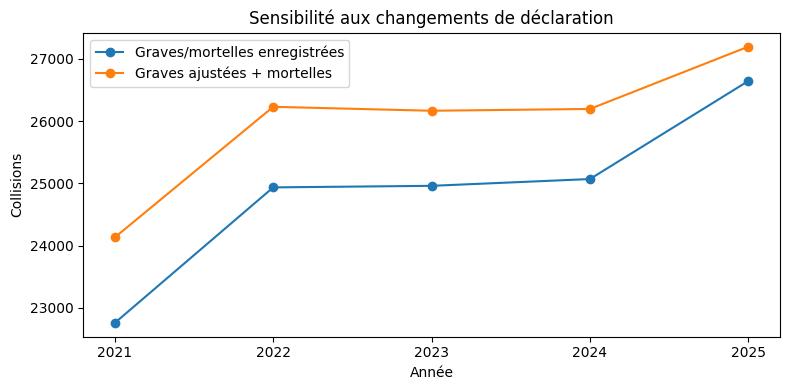

In [11]:
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
trends = []
for year,part in c.groupby("collision_year"):
    trends.append({"Année":int(year),"Graves/mortelles enregistrées":int(part.collision_severity.isin([1,2]).sum()),"Graves ajustées + mortelles":float(part.collision_adjusted_severity_serious.sum()+part.collision_severity.eq(1).sum())})
trends = pd.DataFrame(trends).set_index("Année")
display(trends.round(2))
trends.plot(marker="o",figsize=(8,4))
plt.ylabel("Collisions")
plt.title("Sensibilité aux changements de déclaration")
plt.xticks(trends.index)
plt.tight_layout()
plt.show()


## Ce qui est appris dans le notebook 03

Après ce nettoyage déterministe, médianes, standardisation, vocabulaire d’encodage et modèles seront ajustés sur 2021–2023 seulement. La validation 2024 choisit les paramètres ; 2025 sert à l’évaluation de cette comparaison. Ce test avait déjà été inspecté dans les essais initiaux : une future année indépendante reste nécessaire.

[Source DfT](https://www.gov.uk/government/statistical-data-sets/road-safety-open-data) · [Gravité et changements de déclaration](https://www.gov.uk/government/publications/guide-to-severity-adjustments-for-reported-road-casualty-statistics) · [Prétraitement sans fuite](https://scikit-learn.org/stable/common_pitfalls).
